# LinkAja Syariah 2027 sampai 2032: Simulasi Monte Carlo Solusi Nava

**Rekomendasi kami:** *Nava by LinkAja*, #TheOnlyMuslimAppYouNeed. Tiga pilar: (1) aplikasi Nava, (2) aktivasi awareness lewat KOL, QRIS masjid, dan festival, (3) loyalty lewat Quest, Widget, dan Muhasabah.

Notebook ini menghitung kelayakan solusi dengan simulasi Monte Carlo 10.000 putaran. Semua kode ada di sini, berurutan, dan bisa dijalankan dari atas ke bawah tanpa file lain.

| Bagian | Pertanyaan yang dijawab |
|---|---|
| **0** | Bagaimana simulasi bekerja, dalam bahasa sederhana |
| **1** | Apa yang terjadi bila LinkAja Syariah tidak melakukan apa-apa (baseline)? |
| **2** | Seberapa besar MAU naik dengan solusi Nava dibanding baseline? |
| **3** | Pilar mana yang paling bekerja, dan asumsi mana yang paling menentukan? |
| **4** | Berapa pertumbuhan per tahun, dan berapa biaya yang masih sepadan (titik impas)? |
| **5** | Berapa peluang solusi ini berhasil, dengan dan tanpa mitigasi risiko eksekusi? |

> Semua angka adalah hasil model dari asumsi yang tertulis di notebook ini. Ini bukan prediksi pasti dan bukan angka resmi LinkAja. Angka yang paling dapat dipertahankan adalah persentase kenaikan, bukan level MAU absolut, karena MAU Syariah tidak dipublikasikan.

## 0. Cara kerja simulasi (kata sederhana)

Untuk setiap satu dari 10.000 "kemungkinan dunia 2027 sampai 2032":

1. **Dunia do nothing.** Pengguna terdaftar dan pengguna aktif bulanan (MAU) tumbuh dengan laju yang terus melandai (kurva S, Bass 1969). Di atasnya ditambahkan keacakan: kondisi ekonomi, kemungkinan resesi, kejutan mendadak (misalnya gangguan layanan atau kompetitor), pola Ramadan, dan fluktuasi bulanan.
2. **Dunia dengan solusi.** Dunia acak yang **sama persis**, lalu tiga pilar menambah efek:
   - **Pilar 1 (aplikasi Nava)** menaikkan rasio pengguna aktif terhadap pengguna terdaftar.
   - **Pilar 2 (aktivasi)** menambah pengguna terdaftar baru, yang sebagian menjadi aktif.
   - **Pilar 3 (loyalty)** menaikkan retensi: sekali naik di level, lalu menumpuk sedikit tiap tahun.
   - Besar tiap efek ditarik dari rentang (minimum, paling mungkin, maksimum). Efek dibangun bertahap, bukan seketika, dan saling tumpang tindih. Rasio aktif dibatasi sekitar 12,5% (rasio Muslim Pro).
3. **Bandingkan di dunia yang sama.** Selisih antara dunia solusi dan dunia do nothing murni berasal dari solusi, bukan keberuntungan (bilangan acak bersama, *common random numbers*).
4. **Risiko eksekusi.** Sebuah pilar bisa gagal total. Bagian 5 menghitung peluang berhasil dengan memasukkan kemungkinan itu, dengan dan tanpa rancangan mitigasi.

## 0.1 Setup

In [1]:
import os, itertools
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110})

OUT = "output_notebook"          # grafik juga disimpan sebagai file PNG di folder ini
os.makedirs(OUT, exist_ok=True)

def show(df, digits=2):
    display(df.style.hide(axis="index").format(precision=digits))

### Data publik yang dipakai sebagai jangkar

Pengguna terdaftar LinkAja Syariah: 1,6 juta (akhir 2020), 5,8 juta (Nov 2021), 7,5 juta (Jul 2022), lebih dari 9 juta (Agu 2026), dan sekitar 10 juta (Nov 2026). Pertumbuhan sudah melandai: sekitar 4,5% sampai 6,9% per tahun sejak 2022. Pola cepat lalu melandai ini sesuai kurva S (Bass, 1969). MAU Syariah tidak dipublikasikan, jadi level awalnya dibuat sebagai distribusi, bukan satu angka.

## 0.2 Mesin baseline (kondisi do nothing)

Parameter baseline dibuat sebagai rentang (segitiga atau seragam), lalu satu set parameter ditarik untuk tiap dunia. Kode di bawah mendefinisikan parameter, keacakan (makro AR(1) berekor tebal, resesi, kejutan Poisson, musiman Ramadan), dan fungsi `simulate`.

In [2]:
import matplotlib.pyplot as plt

START_YEAR = 2027
N_YEARS = 6
N_MONTHS = N_YEARS * 12
MAU_CAP_RATIO = 0.35

# (nama, distribusi, argumen)  tri = segitiga(min, modus, maks), uni = uniform(min, maks)
PARAMS = [
    ("R0", "tri", (9.5, 10.0, 10.8)),         # pengguna terdaftar awal (juta)
    ("a0", "tri", (0.05, 0.08, 0.125)),       # rasio MAU / terdaftar awal
    ("g1", "tri", (0.03, 0.055, 0.08)),       # pertumbuhan terdaftar tahun 1
    ("g_inf", "tri", (0.005, 0.015, 0.025)),  # pertumbuhan terdaftar jangka panjang
    ("lam_g", "uni", (0.2, 0.6)),             # peluruhan pertumbuhan terdaftar
    ("h1", "tri", (0.03, 0.08, 0.15)),        # pertumbuhan MAU tahun 1
    ("h_inf", "tri", (0.0, 0.02, 0.04)),      # pertumbuhan MAU jangka panjang
    ("mu_h", "uni", (0.2, 0.7)),              # peluruhan pertumbuhan MAU
    ("kappa", "tri", (-0.10, 0.0, 0.25)),     # perubahan tekanan kompetisi
    ("beta", "tri", (0.0, 1.0, 3.0)),         # sensitivitas MAU terhadap konsumsi
    ("A", "tri", (0.02, 0.06, 0.12)),         # amplitudo Ramadan
    ("shock_rate", "tri", (0.1, 0.3, 0.6)),   # kejadian khusus per tahun
    ("sigma_idio", "tri", (0.005, 0.01, 0.02)),  # noise bulanan MAU
]

MACRO_SIGMA = 0.003
MACRO_RHO = 0.5
MACRO_T_DF = 5
RECESSION_PROB = 0.03
RECESSION_DROP = (0.02, 0.04)
SHOCK_SIZE = (0.02, 0.10)
SHOCK_RECOVERY = 1.0 / 12.0
NOISE_PHI = 0.7
ADDS_NOISE_SIGMA = 0.20

RAMADAN_STARTS = ["2027-02-08", "2028-01-28", "2029-01-16", "2030-01-05",
                  "2030-12-26", "2031-12-15", "2032-12-04"]

NAVY, GOLD, GOLD_DARK = "#1f3b73", "#e6b422", "#b7791f"

In [3]:
def ramadan_weights():
    days = set()
    for s in RAMADAN_STARTS:
        d0 = dt.date.fromisoformat(s)
        days.update(d0 + dt.timedelta(days=i) for i in range(30))
    w = []
    for m in range(N_MONTHS):
        y, mo = START_YEAR + m // 12, m % 12 + 1
        first = dt.date(y, mo, 1)
        nxt = dt.date(y + (mo == 12), mo % 12 + 1, 1)
        nd = (nxt - first).days
        w.append(sum(first + dt.timedelta(days=i) in days for i in range(nd)) / nd)
    return np.array(w)


def draw_parameters(rng, n):
    cols = {}
    for name, dist, args in PARAMS:
        cols[name] = rng.triangular(*args, size=n) if dist == "tri" else rng.uniform(*args, size=n)
    return pd.DataFrame(cols)


def simulate(rng, n):
    p = draw_parameters(rng, n)
    rw = ramadan_weights()

    # simpangan pertumbuhan konsumsi per tahun: AR(1), Student t, resesi langka
    scale_t = np.sqrt(MACRO_T_DF / (MACRO_T_DF - 2))
    dev = np.zeros((n, N_YEARS))
    prev = np.zeros(n)
    for k in range(N_YEARS):
        innov = MACRO_SIGMA * rng.standard_t(MACRO_T_DF, size=n) / scale_t
        rec = rng.random(n) < RECESSION_PROB
        innov = innov - rec * rng.uniform(*RECESSION_DROP, size=n)
        prev = MACRO_RHO * prev + innov
        dev[:, k] = prev
    macro_effect = p["beta"].values[:, None] * dev

    R = p["R0"].values * 1e6
    trend = R * p["a0"].values
    sf = np.ones(n)
    eta = np.zeros(n)
    n_events = np.zeros(n)
    R_path = np.zeros((n, N_MONTHS))
    MAU_path = np.zeros((n, N_MONTHS))
    MAU_sa = np.zeros((n, N_MONTHS))  # MAU tanpa lonjakan Ramadan

    for m in range(N_MONTHS):
        k = m // 12

        # pengguna terdaftar
        g_k = p["g_inf"] + (p["g1"] - p["g_inf"]) * np.exp(-p["lam_g"] * k)
        r_m = (1.0 + g_k.values * (1.0 - p["kappa"].values)) ** (1.0 / 12.0) - 1.0
        R = R * (1.0 + r_m * rng.lognormal(-0.5 * ADDS_NOISE_SIGMA ** 2, ADDS_NOISE_SIGMA, size=n))

        # tren MAU
        h_k = p["h_inf"] + (p["h1"] - p["h_inf"]) * np.exp(-p["mu_h"] * k)
        h_eff = h_k.values * (1.0 - p["kappa"].values) + macro_effect[:, k]
        trend = trend * ((1.0 + h_eff) ** (1.0 / 12.0))

        # kejadian khusus: pangkas lalu pulih
        sf = sf + (1.0 - sf) * SHOCK_RECOVERY
        ev = rng.random(n) < (1.0 - np.exp(-p["shock_rate"].values / 12.0))
        sf = np.where(ev, sf * (1.0 - rng.uniform(*SHOCK_SIZE, size=n)), sf)
        n_events += ev

        # noise bulanan dan musiman Ramadan
        eta = NOISE_PHI * eta + p["sigma_idio"].values * rng.standard_normal(n)
        season = 1.0 + p["A"].values * rw[m]
        R_path[:, m] = R
        MAU_path[:, m] = np.minimum(trend * sf * season * np.exp(eta), MAU_CAP_RATIO * R)
        MAU_sa[:, m] = np.minimum(trend * sf * np.exp(eta), MAU_CAP_RATIO * R)

    drivers = p.copy()
    drivers["macro_effect"] = macro_effect.sum(axis=1)
    drivers["n_events"] = n_events
    return {"R": R_path, "MAU": MAU_path, "MAU_sa": MAU_sa, "drivers": drivers,
            "MAU0": p["R0"].values * 1e6 * p["a0"].values}


def yearly(arr):
    a = arr.reshape(arr.shape[0], N_YEARS, 12)
    return a.mean(axis=2), a[:, :, -1]

Fungsi bantu untuk tabel dan grafik baseline:

In [4]:
def pct_table(avg, scale=1e6):
    rows = []
    for k in range(N_YEARS):
        rows.append({"Tahun": START_YEAR + k,
                     "P5 (batas bawah)": np.percentile(avg[:, k], 5) / scale,
                     "P50 (baseline)": np.percentile(avg[:, k], 50) / scale,
                     "P95 (batas atas)": np.percentile(avg[:, k], 95) / scale})
    return pd.DataFrame(rows)


def tail_table(drivers, target):
    p_lo, p_hi = np.percentile(target, [5, 95])
    bear, bull = drivers[target <= p_lo], drivers[target >= p_hi]
    labels = {"h1": "Pertumbuhan MAU tahun 1", "h_inf": "Pertumbuhan MAU jangka panjang",
              "mu_h": "Kecepatan peluruhan pertumbuhan MAU", "kappa": "Perubahan tekanan kompetisi",
              "n_events": "Jumlah kejadian khusus (6 tahun)", "macro_effect": "Efek makro kumulatif",
              "beta": "Sensitivitas MAU terhadap konsumsi", "A": "Amplitudo Ramadan"}
    rows = []
    for c, lb in labels.items():
        rows.append({"Faktor": lb, "Bearish (<=P5)": bear[c].mean(),
                     "Semua simulasi": drivers[c].mean(), "Bullish (>=P95)": bull[c].mean()})
    return pd.DataFrame(rows)


def month_axis():
    return pd.date_range(f"{START_YEAR}-01-01", periods=N_MONTHS, freq="MS")


def clean(ax):
    ax.grid(alpha=0.25)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


def chart_fan(mau_full, mau_trend, end_vals, fname, scale=1e6):
    x = month_axis()
    p5, p95 = [np.percentile(mau_full, q, axis=0) / scale for q in (5, 95)]
    p50_full = np.percentile(mau_full, 50, axis=0) / scale
    p50_trend = np.percentile(mau_trend, 50, axis=0) / scale
    fig, ax = plt.subplots(figsize=(11, 5.8))
    for i, s in enumerate(RAMADAN_STARTS):
        d0 = pd.Timestamp(s)
        ax.axvspan(d0, d0 + pd.Timedelta(days=30), color=GOLD, alpha=0.22, linewidth=0,
                   label="Bulan Ramadan" if i == 0 else None)
    ax.fill_between(x, p5, p95, color=NAVY, alpha=0.12, linewidth=0, label="Rentang P5 sampai P95")
    ax.plot(x, p95, color=NAVY, lw=0.9, ls="--", alpha=0.5)
    ax.plot(x, p5, color=NAVY, lw=0.9, ls="--", alpha=0.5)
    ax.plot(x, p50_full, color=GOLD_DARK, lw=1.3, label="P50 dengan lonjakan Ramadan")
    ax.plot(x, p50_trend, color=NAVY, lw=2.8, label="P50 garis tren (baseline)")
    for v, y, nm in ((end_vals[2], p95[-1], "P95"), (end_vals[1], p50_trend[-1], "P50"),
                     (end_vals[0], p5[-1], "P5")):
        ax.annotate(f"{nm} (rata2 2032): {v:.2f}", (x[-1], y), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=9, color=NAVY)
    ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=330))
    ax.set_title("Proyeksi Baseline MAU LinkAja Syariah 2027 sampai 2032 (10.000 simulasi)",
                 fontsize=12.5, fontweight="bold")
    ax.set_ylabel("MAU (juta)")
    clean(ax)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(fname, dpi=170)
    plt.show()


def chart_spaghetti(mau_trend, fname, k=120, scale=1e6):
    x = month_axis()
    idx = np.random.default_rng(7).choice(mau_trend.shape[0], size=k, replace=False)
    fig, ax = plt.subplots(figsize=(10.5, 5.6))
    for i in idx:
        ax.plot(x, mau_trend[i] / scale, color="#6f8fc7", lw=0.6, alpha=0.28)
    for q, ls, lw, lb in ((95, "--", 1.4, "P95"), (5, "--", 1.4, "P5"), (50, "-", 2.8, "P50 (baseline)")):
        ax.plot(x, np.percentile(mau_trend, q, axis=0) / scale, color=NAVY, ls=ls, lw=lw, label=lb)
    ax.set_title(f"{k} Lintasan Simulasi Acak dari 10.000 (tanpa musiman Ramadan)",
                 fontsize=12.5, fontweight="bold")
    ax.set_ylabel("MAU (juta)")
    clean(ax)
    ax.legend(loc="upper left", frameon=False)
    fig.tight_layout()
    fig.savefig(fname, dpi=170)
    plt.show()


def chart_hist(target, fname, scale=1e6):
    t = target / scale
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.hist(t, bins=60, color="#8fb0de", edgecolor="white")
    for v, c, lb in zip(np.percentile(t, [5, 50, 95]), ("#b03a2e", NAVY, "#1e8449"), ("P5", "P50", "P95")):
        ax.axvline(v, color=c, lw=2, label=f"{lb}: {v:.2f} juta")
    ax.set_title("Distribusi MAU Rata-rata 2032 (baseline, 10.000 simulasi)", fontsize=12, fontweight="bold")
    ax.set_xlabel("MAU (juta)")
    ax.set_ylabel("jumlah simulasi")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(fname, dpi=160)
    plt.show()

## 0.3 Mesin solusi (tiga pilar)

Besar efek tiap pilar adalah **asumsi tim**: tidak ada data konversi KOL, QRIS masjid, atau retensi untuk LinkAja. Karena itu semuanya ditulis sebagai rentang (minimum / paling mungkin / maksimum), dan Bagian 3 menguji seberapa sensitif hasilnya.

In [5]:
LO, HI = 10, 90         # batas bawah dan atas yang dilaporkan (persentil)
RATIO_CAP = 0.125       # batas rasio aktif/terdaftar: Muslim Pro (5 juta aktif dari 40 juta terdaftar)
EFEK_SEED = 99          # acak terpisah untuk efek solusi, baseline tidak berubah
RISK_SEED = 777         # acak terpisah untuk kegagalan eksekusi
F_GRID = (0.0, 0.1, 0.2, 0.3, 0.4)   # peluang tiap pilar gagal total (asumsi, ditampilkan sebagai rentang)
F_UTAMA = 0.3           # nilai hati-hati yang dipakai sebagai angka utama
MIT_C = 0.10            # mitigasi: peluang semua kanal/fitur satu pilar gagal karena sebab bersama
MIT_Q2 = 0.5            # mitigasi: peluang peluncuran ulang aplikasi juga gagal, bila peluncuran pertama gagal
MIT_TUNDA = 9           # mitigasi: bulan keterlambatan efek bila aplikasi harus diluncurkan ulang
KEYAKINAN = 0.8         # tingkat keyakinan untuk target yang dapat dijanjikan
BASE_USERS_2032 = 92e6 * 1.015 ** 6    # basis LinkAja total 2032: 92 juta tumbuh 1,5% per tahun

# efek tiap pilar (min, modus, maks) dan waktu bangun efek (bulan); satu set parameter solusi
#   m1 : pengali rasio aktif oleh aplikasi Nava (pilar 1)
#   u1 : tambahan pengguna terdaftar dari aplikasi Nava (pilar 1)
#   u2 : tambahan pengguna terdaftar dari aktivasi KOL, masjid, festival (pilar 2)
#   q  : keaktifan pengguna baru relatif terhadap rata-rata (pilar 2)
#   m3 : pengali MAU dari retensi (pilar 3)
#   om : faktor tumpang tindih antarpilar
#   t1, t2, t3 : waktu bangun efek pilar 1, 2, 3
EFEK = dict(m1=(1.05, 1.20, 1.45), u2=(0.03, 0.09, 0.20), u1=(0, 0, 0), q=(0.5, 0.8, 1.0),
            m3=(1.02, 1.08, 1.18), om=(0.7, 1.0), t1=(8, 18), t2=(6, 15), t3=(12, 24),
            g3=(0.0, 0.01, 0.025))   # g3: tambahan pertumbuhan MAU per tahun dari retensi pilar 3 (ASUMSI, belum ada data)
PILAR = {"Pilar 1 (aplikasi Nava)": (True, False, False), "Pilar 2 (aktivasi)": (False, True, False),
         "Pilar 3 (loyalty)": (False, False, True)}
WARNA = {"Baseline": "#1f3b73", "Solusi": "#1e8449"}

# data publik pengguna terdaftar LinkAja Syariah (juta); sumbu: angka tahun = posisi Desember tahun itu
HIST_TERDAFTAR = [(2020.0, 1.6, "Des 2020"), (2021 - 1 / 12, 5.8, "Nov 2021"), (2022 - 5 / 12, 7.5, "Jul 2022"),
                  (2026 - 4 / 12, 9.0, "Agu 2026"), (2026 - 1 / 12, 10.0, "Nov 2026")]

Rumus efek (waktu `t` dalam bulan, `tau` waktu efek terbangun):

```
Rampa efek pilar i:        r_i(t) = 1 - exp(-t / tau_i)
Terdaftar dengan solusi:   R'(t)  = R(t) · (1 + U2·r_2(t) + U1·r_1(t))
Faktor pilar 1:            f1(t)  = 1 + (M1 - 1)·r_1(t)
Faktor pengguna baru:      f2(t)  = 1 + q·(U2·r_2(t) + U1·r_1(t))
Faktor pilar 3:            f3(t)  = (1 + (M3 - 1)·r_3(t)) · (1 + G3)^( r_3(t)·t/12 )     (retensi menumpuk)
Kenaikan MAU:              L(t)   = omega · ( f1·f2·f3 - 1 )         (omega = 1 bila satu pilar)
MAU dengan solusi:         MAU'(t) = min( MAU(t)·(1 + L(t)),  rasio_maks · R'(t) )
```

In [6]:
# ---------------------------------------------------------------- model efek solusi

def tri(rng, a, n):
    if a[0] == a[2]:
        return np.full((n, 1), float(a[1]))
    return rng.triangular(*a, size=(n, 1))


def tarik_efek(n, s):
    rng = np.random.default_rng(EFEK_SEED)
    p = {k: tri(rng, s[k], n) for k in ("m1", "u2", "u1", "q", "m3")}
    p["om"] = rng.uniform(*s["om"], size=(n, 1))
    for k in ("t1", "t2", "t3"):
        p[k] = rng.uniform(*s[k], size=(n, 1))
    p["g3"] = tri(rng, s["g3"], n)    # ditarik terakhir agar tarikan parameter lain tidak berubah
    return p


def hitung_efek(p, pilar=(True, True, True), tunda=0):
    # kenaikan MAU relatif (up) dan kenaikan pengguna terdaftar relatif (reg_up), tiap bulan
    # tunda: bulan keterlambatan efek pilar 1 dan 3 (aplikasi diluncurkan ulang)
    t = np.arange(1, N_MONTHS + 1)[None, :]
    tl = np.clip(t - tunda, 0, None)
    r1, r3 = [1 - np.exp(-tl / p[k]) for k in ("t1", "t3")]
    r2 = 1 - np.exp(-t / p["t2"])
    p1, p2, p3 = pilar
    reg_up = np.zeros_like(r1)
    if p2:
        reg_up = reg_up + p["u2"] * r2
    if p1:
        reg_up = reg_up + p["u1"] * r1
    f1 = 1 + (p["m1"] - 1) * r1 if p1 else 1.0
    # pilar 3: kenaikan level (m3) ditambah retensi yang menumpuk: pertumbuhan tambahan g3 per tahun sejak efek berjalan
    f3 = (1 + (p["m3"] - 1) * r3) * (1 + p["g3"]) ** (r3 * tl / 12) if p3 else 1.0
    up = f1 * (1 + p["q"] * reg_up) * f3 - 1
    if sum(pilar) > 1:
        up = up * p["om"]
    return up, reg_up


def terapkan(mau, R, up, reg_up):
    # rasio aktif dibatasi 12,5% (atau rasio baseline bila sudah lebih tinggi)
    reg_s = R * (1 + reg_up)
    cap = np.minimum(np.maximum(RATIO_CAP, mau / R), MAU_CAP_RATIO)
    return np.minimum(mau * (1 + up), cap * reg_s), reg_s


def jalankan_solusi(res, n):
    p = tarik_efek(n, EFEK)
    up, reg_up = hitung_efek(p)
    mau_s, reg_s = terapkan(res["MAU"], res["R"], up, reg_up)
    mau_sa, _ = terapkan(res["MAU_sa"], res["R"], up, reg_up)
    out = dict(p=p, mau=mau_s, mau_sa=mau_sa, reg=reg_s, up=up, reg_up=reg_up)
    for pn, flags in PILAR.items():
        u1, r1 = hitung_efek(p, flags)
        out[pn], _ = terapkan(res["MAU"], res["R"], u1, r1)
    return out

Fungsi bantu solusi: tabel hasil dan regresi untuk riwayat sebelum 2027.

In [7]:
def pc(x, axis=None):
    return np.percentile(x, [LO, 50, HI], axis=axis)


def regresi_historis():
    # regresi saturasi eksponensial R(t) = K - c exp(-b (t - 2020)) pada titik data publik
    x = np.array([h[0] for h in HIST_TERDAFTAR]); y = np.array([h[1] for h in HIST_TERDAFTAR])
    best = None
    for b in np.linspace(0.05, 3, 600):
        A = np.c_[np.ones_like(x), -np.exp(-b * (x - 2020))]
        coef = np.linalg.lstsq(A, y, rcond=None)[0]
        sse = ((A @ coef - y) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, b, coef)
    sse, b, (K, c) = best
    r2 = 1 - sse / ((y - y.mean()) ** 2).sum()
    return (lambda t: K - c * np.exp(-b * (np.asarray(t) - 2020))), r2

In [8]:
# ---------------------------------------------------------------- tabel

def tabel_utama(res, sol):
    # MAU rata-rata tahunan (juta)
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    rows = []
    for k in range(N_YEARS):
        r = {"Tahun": START_YEAR + k}
        r["Do nothing P10"], r["Do nothing P50"], r["Do nothing P90"] = pc(yb[:, k] / 1e6)
        r["Solusi P10"], r["Solusi P50"], r["Solusi P90"] = pc(ys[:, k] / 1e6)
        rows.append(r)
    return pd.DataFrame(rows)


def tabel_indeks(res, sol):
    # MAU berindeks (Des 2026 = 100, per simulasi) dan uji "kasus buruk solusi vs kasus baik do nothing"
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    m0 = res["MAU0"][:, None]
    ib, is_ = pc(yb / m0 * 100, axis=0), pc(ys / m0 * 100, axis=0)
    rows = []
    for k in range(N_YEARS):
        rows.append({"Tahun": START_YEAR + k, "Do nothing P10": ib[0, k], "Do nothing P50": ib[1, k],
                     "Do nothing P90": ib[2, k], "Solusi P10": is_[0, k], "Solusi P50": is_[1, k], "Solusi P90": is_[2, k],
                     "P10 solusi di atas P90 do nothing": bool(is_[0, k] > ib[2, k]),
                     "Solusi menang di simulasi yang sama (%)": np.mean(ys[:, k] > yb[:, k]) * 100})
    return pd.DataFrame(rows)


def tabel_uplift_tahun(res, sol):
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    rows = []
    for k in range(N_YEARS):
        r = {"Tahun": START_YEAR + k}
        r["Kenaikan P10 (%)"], r["Kenaikan P50 (%)"], r["Kenaikan P90 (%)"] = pc((ys[:, k] / yb[:, k] - 1) * 100)
        rows.append(r)
    return pd.DataFrame(rows)


def tabel_ringkasan(res, sol):
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    _, rb = yearly(res["R"]); _, rs = yearly(sol["reg"])
    mau0 = res["MAU0"]
    u = pc((ys[:, -1] / yb[:, -1] - 1) * 100)
    ratio = sol["mau"][:, -1] / sol["reg"][:, -1]
    cap_aktif = np.mean(ratio >= RATIO_CAP - 1e-9) * 100
    rows = [
        ("Kenaikan MAU 2032 P10 (%)", u[0]), ("Kenaikan MAU 2032 P50 (%)", u[1]), ("Kenaikan MAU 2032 P90 (%)", u[2]),
        ("MAU 2032 do nothing, P50 (juta)", np.median(yb[:, -1]) / 1e6),
        ("MAU 2032 dengan solusi, P50 (juta)", np.median(ys[:, -1]) / 1e6),
        ("Tambahan MAU 2032, median berpasangan (juta)", np.median(ys[:, -1] - yb[:, -1]) / 1e6),
        ("Pertumbuhan MAU per tahun do nothing, P50 (%)", (np.median(yb[:, -1] / mau0) ** (1 / 5.5) - 1) * 100),
        ("Pertumbuhan MAU per tahun dengan solusi, P50 (%)", (np.median(ys[:, -1] / mau0) ** (1 / 5.5) - 1) * 100),
        ("Pertumbuhan MAU tahun 1 dengan solusi, P50 (%)", np.median(ys[:, 0] / mau0 - 1) * 100),
        ("Kenaikan pengguna terdaftar 2032, P50 (%)", np.median(rs[:, -1] / rb[:, -1] - 1) * 100),
        ("Tambahan pengguna terdaftar 2032 (juta)", np.median(rs[:, -1] - rb[:, -1]) / 1e6),
        ("Pangsa basis LinkAja 2032, dengan solusi (%)", np.median(rs[:, -1]) / BASE_USERS_2032 * 100),
        ("Rasio aktif 2032 do nothing, P50 (%)", np.median(res["MAU"][:, -1] / res["R"][:, -1]) * 100),
        ("Rasio aktif 2032 dengan solusi, P50 (%)", np.median(ratio) * 100),
        ("Simulasi yang kena batas rasio aktif 12,5% (%)", cap_aktif),
        ("Solusi lebih tinggi dari do nothing pada simulasi yang sama (%)", np.mean(ys[:, -1] > yb[:, -1]) * 100),
        ("Peluang MAU solusi melewati P90 do nothing (%)", np.mean(ys[:, -1] > np.percentile(yb[:, -1], HI)) * 100),
    ]
    return pd.DataFrame(rows, columns=["Ukuran", "Nilai"])


def tabel_pilar(res, sol):
    yb, _ = yearly(res["MAU"])
    rows = []
    for pn in list(PILAR) + ["Gabungan (setelah tumpang tindih)"]:
        arr = sol["mau"] if pn.startswith("Gabungan") else sol[pn]
        q = pc((yearly(arr)[0][:, -1] / yb[:, -1] - 1) * 100)
        rows.append({"Pilar": pn, "Kenaikan MAU 2032 P50 (%)": q[1], "P10 (%)": q[0], "P90 (%)": q[2]})
    return pd.DataFrame(rows)


def tabel_asumsi():
    nama = {"m1": "Pilar 1: pengali rasio aktif (aplikasi Nava)", "u1": "Pilar 1: tambahan terdaftar dari aplikasi",
            "u2": "Pilar 2: tambahan terdaftar (KOL, masjid, festival)", "q": "Pilar 2: keaktifan pengguna baru",
            "m3": "Pilar 3: pengali MAU dari retensi", "om": "Tumpang tindih antarpilar (pengali efek gabungan)",
            "g3": "Pilar 3: tambahan pertumbuhan MAU per tahun dari retensi (menumpuk)",
            "t1": "Waktu bangun efek pilar 1 (bulan)", "t2": "Waktu bangun efek pilar 2 (bulan)",
            "t3": "Waktu bangun efek pilar 3 (bulan)"}
    return pd.DataFrame([(lb, ("seragam " if len(EFEK[k]) == 2 else "") + " / ".join(f"{v:g}" for v in EFEK[k]))
                         for k, lb in nama.items()], columns=["Parameter", "Min / modus / maks"])


def tabel_sensitivitas(res, sol):
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    u = ys[:, -1] / yb[:, -1] - 1
    rows = []
    for k, v in sol["p"].items():
        if v.std() > 0:     # parameter konstan (u1 = 0) dilewati
            rows.append((k, pd.Series(v[:, 0]).rank().corr(pd.Series(u).rank())))
    df = pd.DataFrame(rows, columns=["parameter", "spearman"])
    return df.reindex(df["spearman"].abs().sort_values(ascending=False).index).reset_index(drop=True)


def tabel_kewajaran(res):
    # uji kewajaran baseline terhadap jangkar data
    r0 = res["drivers"]["R0"].values * 1e6
    g_reg = res["R"][:, 11] / r0 - 1
    g_mau = res["MAU_sa"][:, 11] / res["MAU0"] - 1
    share = res["R"][:, -1] / BASE_USERS_2032
    rows = [
        ("Pertumbuhan terdaftar 2027 (%)", *(pc(g_reg) * 100), "riwayat 2022 ke 2026: 4,5 sampai 6,9 per tahun"),
        ("Pertumbuhan tren MAU 2027 (%)", *(pc(g_mau) * 100), "MAU LinkAja total +5% (2026); MAU Syariah +20% (2024)"),
        ("Pangsa basis LinkAja 2032 (%)", *(pc(share) * 100), "2022: 8,6; 2026: 10,9"),
    ]
    df = pd.DataFrame(rows, columns=["Ukuran", "P10", "P50", "P90", "Jangkar data"])
    df.loc[len(df)] = ["Simulasi dengan pertumbuhan terdaftar 2027 dalam rentang riwayat (%)",
                       np.nan, np.mean((g_reg >= 0.045) & (g_reg <= 0.069)) * 100, np.nan, "4,5 sampai 6,9 per tahun"]
    return df

Fungsi grafik solusi:

In [9]:
def simpan(fig, fname, dpi=190):
    fig.savefig(fname, dpi=dpi, bbox_inches="tight")
    plt.show()

In [10]:
def chart_utama(res, sol, fname):
    # satu grafik: do nothing vs solusi, MAU berindeks (Des 2026 = 100), pita P10 sampai P90
    # riwayat sebelum 2027: regresi pengguna terdaftar, dengan asumsi rasio aktif tetap
    yrs = np.arange(2027, 2033)
    c_b, c_s = WARNA["Baseline"], WARNA["Solusi"]
    f, r2 = regresi_historis()
    base = float(f(2026.0))
    fig, ax = plt.subplots(figsize=(10.5, 5.8))

    tt = np.linspace(2020.0, 2026.0, 200)
    ax.plot(tt, f(tt) / base * 100, "-", color="#222831", lw=2.4, label="Historis (estimasi regresi)")
    ax.plot([h[0] for h in HIST_TERDAFTAR], [h[1] / base * 100 for h in HIST_TERDAFTAR], "o", color="#222831",
            ms=6.5, label="Data publik pengguna terdaftar")

    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    m0 = res["MAU0"][:, None]
    pb, ps = pc(yb / m0 * 100, axis=0), pc(ys / m0 * 100, axis=0)
    xx = np.r_[2026, yrs]
    ax.plot(xx, np.r_[100, pb[1]], "--o", color=c_b, lw=2.6, ms=6, label="Do nothing")
    ax.plot(xx, np.r_[100, ps[1]], "-o", color=c_s, lw=2.8, ms=6, label="Dengan solusi Nava")
    ax.fill_between(yrs, pb[0], pb[2], color=c_b, alpha=0.14, lw=0)
    ax.fill_between(yrs, ps[0], ps[2], color=c_s, alpha=0.16, lw=0)
    ax.text(2032.2, pb[1][-1], f"{pb[1][-1]:.0f}", color=c_b, fontsize=11, fontweight="bold", va="center")
    ax.text(2032.2, ps[1][-1], f"{ps[1][-1]:.0f}", color=c_s, fontsize=11, fontweight="bold", va="center")
    ax.annotate("", xy=(2032.75, ps[1][-1]), xytext=(2032.75, pb[1][-1]), arrowprops=dict(arrowstyle="<->", color="#333", lw=1.3))
    ax.text(2032.9, (ps[1][-1] + pb[1][-1]) / 2, f"+{(ps[1][-1] / pb[1][-1] - 1) * 100:.0f}%", fontsize=10.5,
            fontweight="bold", va="center")
    ax.axvline(2026, color="#888", lw=0.8, ls=":")
    cb, cs = [np.median(((yearly(m)[0][:, -1] / res["MAU0"]) ** (1 / TAHUN_EFEKTIF) - 1) * 100) for m in (res["MAU_sa"], sol["mau_sa"])]
    ax.text(2026.1, 190, f"Pertumbuhan per tahun (Des 2026 sampai 2032)\nDo nothing {cb:.1f}%   |   Nava {cs:.1f}%",
            fontsize=10, fontweight="bold", color="#222", va="top")
    ax.text(2026.1, 14, "proyeksi", fontsize=8.5, color="#666"); ax.text(2025.9, 14, "historis", fontsize=8.5, color="#666", ha="right")
    ax.set_xlim(2019.7, 2033.6); ax.set_xticks(range(2020, 2033, 2))
    ax.set_ylabel("MAU, indeks (Des 2026 = 100)")
    ax.set_title("LinkAja Syariah: Do nothing vs Dengan Solusi Nava", fontsize=13, fontweight="bold")
    ax.legend(loc="upper left", frameon=False, fontsize=9.5)
    fig.text(0.01, -0.02, f"Garis = median, pita = P{LO} sampai P{HI}. Sebelum 2027: MAU diasumsikan mengikuti pengguna terdaftar "
             "(rasio aktif tetap), 2023 sampai 2025 dari regresi, bukan data.", fontsize=8, color="#555")
    clean(ax)
    fig.tight_layout()
    simpan(fig, fname, 200)


def chart_lintasan(res, sol, fname, n_path=60, seed=7):
    # lintasan acak: do nothing (kiri) dan dengan solusi (kanan); lintasan ke-i di kedua sisi adalah dunia acak yang sama
    x = month_axis()
    m0 = res["MAU0"][:, None]
    ib, is_ = res["MAU_sa"] / m0 * 100, sol["mau_sa"] / m0 * 100
    idx = np.random.default_rng(seed).choice(ib.shape[0], n_path, replace=False)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharey=True)
    for ax, arr, c, ttl in ((axes[0], ib, WARNA["Baseline"], "Do nothing"),
                            (axes[1], is_, WARNA["Solusi"], "Dengan solusi Nava")):
        ax.plot(x, arr[idx].T, color=c, alpha=0.17, lw=0.8)
        lo, md, hi = pc(arr, axis=0)
        ax.plot(x, lo, color=c, ls="--", lw=1.7, label=f"P{LO}")
        ax.plot(x, hi, color=c, ls="--", lw=1.7, label=f"P{HI}")
        ax.plot(x, md, color=c, lw=3.2, label="Median (P50)")
        ax.axhline(100, color="#888", lw=0.8, ls=":")
        ax.text(x[-1], md[-1], f"  {md[-1]:.0f}", color=c, fontsize=11, fontweight="bold", va="center")
        ax.set_title(ttl, fontsize=12, fontweight="bold")
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        clean(ax)
    axes[0].set_ylabel("MAU, indeks (Des 2026 = 100)")
    fig.suptitle(f"Lintasan Acak MAU 2027 sampai 2032 ({n_path} dari {ib.shape[0]:,} simulasi, tanpa musiman Ramadan)",
                 fontsize=13, fontweight="bold")
    fig.text(0.01, -0.02, "Lintasan ke-i di kiri dan kanan berasal dari dunia acak yang sama (makro, kompetisi, kejadian khusus); "
             "perbedaannya hanya solusi. Angka di ujung kanan = Desember 2032.", fontsize=8.5, color="#555")
    fig.tight_layout()
    simpan(fig, fname)


def chart_distribusi(res, sol, fname):
    # kiri: sebaran MAU 2032 berindeks; kanan: sebaran kenaikan pada simulasi yang sama
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    m0 = res["MAU0"]
    a, b = yb[:, -1] / m0 * 100, ys[:, -1] / m0 * 100
    ybl, _ = yearly(res["MAU"]); ysl, _ = yearly(sol["mau"])
    u = (ysl[:, -1] / ybl[:, -1] - 1) * 100
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
    bins = np.linspace(min(a.min(), b.min()), np.percentile(b, 99.7), 70)
    for v, c, lb in ((a, WARNA["Baseline"], "Do nothing"), (b, WARNA["Solusi"], "Dengan solusi")):
        a1.hist(v, bins=bins, color=c, alpha=0.5, edgecolor="white", label=f"{lb} (P50 {np.median(v):.0f})")
        a1.axvline(np.median(v), color=c, lw=2)
    a1.set_xlim(bins[0], bins[-1])
    a1.set_title("Sebaran MAU 2032 (indeks, Des 2026 = 100)", fontsize=12, fontweight="bold")
    a1.set_xlabel("indeks MAU 2032"); a1.set_ylabel("jumlah simulasi"); a1.legend(frameon=False, fontsize=9.5); clean(a1)
    a2.hist(u, bins=70, color=WARNA["Solusi"], alpha=0.55, edgecolor="white")
    a2.axvline(np.median(u), color=WARNA["Solusi"], lw=2.2, label=f"Median {np.median(u):.0f}%")
    a2.axvline(np.percentile(u, LO), color="#555", lw=1.5, ls="--", label=f"P{LO} {np.percentile(u, LO):.0f}%, P{HI} {np.percentile(u, HI):.0f}%")
    a2.axvline(np.percentile(u, HI), color="#555", lw=1.5, ls="--")
    a2.axvline(0, color="#222", lw=1.2)
    a2.set_title("Sebaran kenaikan MAU 2032 vs do nothing (simulasi yang sama)", fontsize=12, fontweight="bold")
    a2.set_xlabel(f"kenaikan (%), terendah {u.min():.0f}%"); a2.legend(frameon=False, fontsize=9.5); clean(a2)
    fig.tight_layout()
    simpan(fig, fname)


def chart_pilar(res, sol, fname):
    yb, _ = yearly(res["MAU"])
    kat = ["Pilar 1\nAplikasi Nava", "Pilar 2\nAktivasi", "Pilar 3\nLoyalty", "Gabungan"]
    keys = list(PILAR) + [None]
    med, lo, hi = [], [], []
    for kk in keys:
        arr = sol["mau"] if kk is None else sol[kk]
        q = pc((yearly(arr)[0][:, -1] / yb[:, -1] - 1) * 100)
        med.append(q[1]); lo.append(q[1] - q[0]); hi.append(q[2] - q[1])
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    cols = ["#5b8c5a", "#5b8c5a", "#5b8c5a", WARNA["Solusi"]]
    xs = np.arange(len(kat))
    ax.bar(xs, med, 0.55, color=cols, yerr=[lo, hi], capsize=4, error_kw=dict(lw=1.2, alpha=0.7))
    for xx, v, h in zip(xs, med, hi):
        ax.text(xx, v + h + 1, f"{v:.1f}%".replace(".", ","), ha="center", fontsize=10.5, fontweight="bold")
    ax.set_xticks(xs); ax.set_xticklabels(kat)
    ax.set_ylabel("Kenaikan MAU 2032 vs do nothing (%)")
    ax.set_title(f"Kontribusi Tiap Pilar (pilar berjalan sendiri; median, garis = P{LO} sampai P{HI})", fontsize=11.5, fontweight="bold")
    clean(ax)
    fig.tight_layout()
    simpan(fig, fname, 170)


def chart_uplift(res, sol, fname):
    x = month_axis()
    lo, md, hi = pc((sol["mau_sa"] / res["MAU_sa"] - 1) * 100, axis=0)
    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    ax.fill_between(x, lo, hi, color=WARNA["Solusi"], alpha=0.16, linewidth=0, label=f"P{LO} sampai P{HI}")
    ax.plot(x, md, color=WARNA["Solusi"], lw=2.8, label=f"Median (Des 2032: {md[-1]:.0f}%)")
    ax.axhline(0, color="#222", lw=1)
    ax.set_title("Kenaikan MAU terhadap Do Nothing dari Waktu ke Waktu (efek dibangun bertahap)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Kenaikan MAU vs do nothing (%)")
    clean(ax)
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout()
    simpan(fig, fname, 170)

Fungsi untuk peluang berhasil (risiko eksekusi) dan analisis pertumbuhan:

In [11]:
# ---------------------------------------------------------------- peluang berhasil (risiko eksekusi)

def hasil_kombinasi(res, sol, tunda=0):
    # MAU 2032 (rata-rata tahunan) untuk tiap kombinasi pilar yang berjalan: (p1, p2, p3)
    out = {}
    for flags in itertools.product([True, False], repeat=3):
        if not any(flags):
            out[flags] = yearly(res["MAU"])[0][:, -1].copy()
            continue
        up, reg_up = hitung_efek(sol["p"], flags, tunda if (flags[0] or flags[2]) else 0)
        mau, _ = terapkan(res["MAU"], res["R"], up, reg_up)
        out[flags] = yearly(mau)[0][:, -1]
    return out


def siapkan_risiko(res, sol):
    return yearly(res["MAU"])[0][:, -1], hasil_kombinasi(res, sol, 0), hasil_kombinasi(res, sol, MIT_TUNDA)


def simulasi_risiko(kb, f, mitigasi=False):
    # tanpa mitigasi: tiap pilar gagal total dengan peluang f; pilar 3 hanya jalan bila aplikasi jalan.
    # dengan mitigasi: (1) aplikasi diuji lebih dulu dan boleh diluncurkan ulang sekali (peluang gagal lagi MIT_Q2, efek tertunda),
    # (2) pilar 2 dan 3 terdiri dari tiga kanal atau fitur paralel, pilar gagal hanya bila ketiganya gagal (MIT_C sebab bersama).
    yb, o0, o1 = kb
    n = len(yb)
    u = np.random.default_rng(RISK_SEED).random((n, 4))
    if not mitigasi:
        ok1, ok2 = u[:, 0] >= f, u[:, 1] >= f
        ok3, late = (u[:, 2] >= f) & ok1, np.zeros(n, bool)
    else:
        a1 = u[:, 0] >= f
        late = (~a1) & (u[:, 3] >= MIT_Q2)
        ok1 = a1 | late
        f_par = MIT_C + (1 - MIT_C) * f ** 3
        ok2, ok3 = u[:, 1] >= f_par, (u[:, 2] >= f_par) & ok1
    ys = np.empty(n)
    for flags in itertools.product([True, False], repeat=3):
        m = (ok1 == flags[0]) & (ok2 == flags[1]) & (ok3 == flags[2])
        for lt, o in ((False, o0), (True, o1)):
            mm = m & (late == lt)
            if mm.any():
                ys[mm] = o[flags][mm]
    return ys, yb, (ok1, ok2, ok3)


def tabel_peluang(res, sol):
    kb = siapkan_risiko(res, sol)
    yb90 = np.percentile(kb[0], HI)
    rows = []
    for mit in (False, True):
        for f in F_GRID:
            ys, yb, _ = simulasi_risiko(kb, f, mit)
            u = (ys / yb - 1) * 100
            rows.append({"Rancangan": "Dengan mitigasi" if mit else "Tanpa mitigasi",
                         "Peluang pilar gagal awal (%)": f * 100,
                         "Lebih tinggi dari do nothing (%)": np.mean(u > 1e-9) * 100,
                         "Kenaikan MAU minimal 10% (%)": np.mean(u >= 10) * 100,
                         "Kenaikan MAU minimal 20% (%)": np.mean(u >= 20) * 100,
                         "Kenaikan MAU minimal 30% (%)": np.mean(u >= 30) * 100,
                         "Melewati P90 do nothing (%)": np.mean(ys > yb90) * 100,
                         "Kenaikan MAU median (%)": np.median(u),
                         f"Target kenaikan dengan keyakinan {KEYAKINAN * 100:.0f}% (%)": np.percentile(u, (1 - KEYAKINAN) * 100)})
    return pd.DataFrame(rows)


def tabel_kondisi(res, sol, f=F_UTAMA, mitigasi=False):
    # kenaikan median menurut pilar mana yang benar-benar berjalan, dan peluang tiap kondisi
    kb = siapkan_risiko(res, sol)
    ys, yb, (p1, p2, p3) = simulasi_risiko(kb, f, mitigasi)
    u = (ys / yb - 1) * 100
    nama = lambda a, b, c: " + ".join(x for x, k in (("Pilar 1", a), ("Pilar 2", b), ("Pilar 3", c)) if k) or "Tidak ada yang berjalan"
    rows = []
    for flags in itertools.product([True, False], repeat=3):
        m = (p1 == flags[0]) & (p2 == flags[1]) & (p3 == flags[2])
        if m.sum() == 0:
            continue
        rows.append({"Pilar yang berjalan": nama(*flags), "Peluang kondisi (%)": m.mean() * 100,
                     "Kenaikan MAU median (%)": np.median(u[m]),
                     "Peluang melewati P90 do nothing (%)": np.mean(ys[m] > np.percentile(yb, HI)) * 100})
    return pd.DataFrame(rows).sort_values("Peluang kondisi (%)", ascending=False).reset_index(drop=True)


def chart_peluang(res, sol, fname):
    kb = siapkan_risiko(res, sol)
    xs = np.linspace(0, 60, 121)
    c_no, c_mit, c_ref = "#c0762b", "#1e8449", "#888"
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.3), gridspec_kw={"width_ratios": [1.3, 1]})
    for lb, f, mit, c, lw, ls in ((f"Tanpa risiko eksekusi", 0.0, False, c_ref, 1.8, "--"),
                                  (f"Tanpa mitigasi (pilar gagal {F_UTAMA * 100:.0f}%)", F_UTAMA, False, c_no, 2.6, "-"),
                                  (f"Dengan mitigasi (pilar gagal awal {F_UTAMA * 100:.0f}%)", F_UTAMA, True, c_mit, 3.2, "-")):
        ys, yb, _ = simulasi_risiko(kb, f, mit)
        u = (ys / yb - 1) * 100
        a1.plot(xs, [np.mean(u >= x) * 100 for x in xs], color=c, lw=lw, ls=ls, label=lb)
        if mit:
            tgt = np.percentile(u, (1 - KEYAKINAN) * 100)
            a1.plot([tgt], [KEYAKINAN * 100], "o", color=c, ms=9)
            a1.annotate(f"target dengan keyakinan {KEYAKINAN * 100:.0f}%:\nkenaikan minimal {tgt:.0f}%", xy=(tgt, KEYAKINAN * 100),
                        xytext=(tgt + 7, 88), fontsize=9.5, color=c, fontweight="bold", arrowprops=dict(arrowstyle="-", color=c))
    a1.axhline(KEYAKINAN * 100, color="#aaa", ls=":", lw=1)
    a1.set_xlabel("target kenaikan MAU 2032 vs do nothing (%)"); a1.set_ylabel("peluang mencapai target (%)")
    a1.set_title("Peluang Mencapai Target Kenaikan MAU", fontsize=12, fontweight="bold")
    a1.set_ylim(0, 102); a1.legend(frameon=False, fontsize=9, loc="lower left"); clean(a1)
    defs = [("lebih baik dari\ndo nothing", lambda u, ys, yb90: np.mean(u > 1e-9)),
            ("kenaikan\nminimal 10%", lambda u, ys, yb90: np.mean(u >= 10)),
            ("kenaikan\nminimal 20%", lambda u, ys, yb90: np.mean(u >= 20)),
            ("melewati P90\ndo nothing", lambda u, ys, yb90: np.mean(ys > yb90))]
    yb90 = np.percentile(kb[0], HI)
    x = np.arange(len(defs)); w = 0.36
    for off, mit, c, lb in ((-w / 2, False, c_no, "tanpa mitigasi"), (w / 2, True, c_mit, "dengan mitigasi")):
        ys, yb, _ = simulasi_risiko(kb, F_UTAMA, mit)
        u = (ys / yb - 1) * 100
        v = [fn(u, ys, yb90) * 100 for _, fn in defs]
        a2.bar(x + off, v, w, color=c, label=lb)
        for xx, vv in zip(x + off, v):
            a2.text(xx, vv + 1.5, f"{vv:.0f}", ha="center", fontsize=9, fontweight="bold")
    a2.axhline(KEYAKINAN * 100, color="#aaa", ls=":", lw=1)
    a2.set_xticks(x); a2.set_xticklabels([d[0] for d in defs], fontsize=9)
    a2.set_ylabel("peluang berhasil (%)"); a2.set_ylim(0, 108)
    a2.set_title(f"Peluang Berhasil menurut Definisi (pilar gagal awal {F_UTAMA * 100:.0f}%)", fontsize=11.5, fontweight="bold")
    a2.legend(frameon=False, fontsize=9, loc="upper right"); clean(a2)
    fig.tight_layout()
    simpan(fig, fname)

In [12]:
# ---------------------------------------------------------------- pertumbuhan per tahun, titik impas, audit asumsi

TAHUN_EFEKTIF = 5.5   # Des 2026 sampai pertengahan 2032 (rata-rata tahunan 2032)
BIAYA_ILUSTRASI = (10, 25, 50, 100)   # miliar rupiah, total 2027 sampai 2032; ILUSTRASI, bukan data biaya proposal


def tabel_cagr(res, sol):
    # pertumbuhan MAU per tahun (CAGR) dan total pertumbuhan, per simulasi, dilaporkan P10/P50/P90
    m0 = res["MAU0"]
    rows = []
    for nama, mau in (("Do nothing", res["MAU_sa"]), ("Dengan solusi Nava", sol["mau_sa"])):
        y, _ = yearly(mau)
        a = (y[:, -1] / m0) ** (1 / TAHUN_EFEKTIF) - 1
        b = (y[:, -1] / y[:, 0]) ** (1 / (N_YEARS - 1)) - 1
        t = y[:, -1] / m0 - 1
        r = {"Kondisi": nama}
        for lb, v in (("CAGR Des 2026 sampai 2032 (%/tahun)", a), ("CAGR 2027 sampai 2032 (%/tahun)", b),
                      ("Total pertumbuhan 2032 vs Des 2026 (%)", t)):
            q = pc(v * 100)
            r[lb + " P10"], r[lb + " P50"], r[lb + " P90"] = q
        rows.append(r)
    return pd.DataFrame(rows)


def tabel_pertumbuhan_tahunan(res, sol):
    # pertumbuhan median tiap tahun terhadap tahun sebelumnya (rata-rata tahunan); 2027 terhadap MAU Des 2026
    m0 = res["MAU0"]
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    rows = []
    for k in range(N_YEARS):
        pb = yb[:, k] / (m0 if k == 0 else yb[:, k - 1]) - 1
        ps = ys[:, k] / (m0 if k == 0 else ys[:, k - 1]) - 1
        rows.append({"Tahun": START_YEAR + k, "Do nothing P50 (%)": np.median(pb) * 100,
                     "Dengan solusi Nava P50 (%)": np.median(ps) * 100,
                     "Dengan solusi Nava P10 (%)": np.percentile(ps, LO) * 100,
                     "Dengan solusi Nava P90 (%)": np.percentile(ps, HI) * 100})
    return pd.DataFrame(rows)


def tabel_titik_impas(res, sol):
    # kenaikan MAU dalam tahun-pengguna (MAU rata-rata tahunan dijumlah 2027 sampai 2032), dan ARPU minimal agar biaya tertutup
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    tp = (ys - yb).sum(axis=1) / 1e6   # juta tahun-pengguna tambahan
    q = np.percentile(tp, [LO, 50, HI])
    rows = []
    for c in BIAYA_ILUSTRASI:
        r = {"Total biaya 2027 sampai 2032 (Rp miliar, ilustrasi)": c}
        for lb, v in zip((f"P{HI}", "P50", f"P{LO}"), (q[2], q[1], q[0])):
            r[f"Pendapatan bersih minimal per MAU tambahan per tahun, pada {lb} (Rp ribu)"] = c * 1e9 / (v * 1e6) / 1e3
        rows.append(r)
    out = pd.DataFrame(rows)
    out.insert(1, "Tahun-pengguna tambahan P10 / P50 / P90 (juta)", f"{q[0]:.2f} / {q[1]:.2f} / {q[2]:.2f}")
    return out


def tabel_audit_asumsi(res):
    # apakah asumsi yang tampak konservatif menahan hasil? tiap baris mengubah satu asumsi, lainnya tetap
    global RATIO_CAP
    asli = RATIO_CAP
    yb, _ = yearly(res["MAU_sa"]); m0 = res["MAU0"]; n = len(m0)
    varian = [("Model yang dipakai (acuan)", {}, None),
              ("Batas rasio aktif 15% (acuan 12,5%)", {}, 0.15),
              ("Tanpa batas rasio aktif (hanya batas 35% model baseline)", {}, 0.35),
              ("Tanpa diskon tumpang tindih pilar (omega = 1)", {"om": (1.0, 1.0)}, None),
              ("Lintas jual dari basis LinkAja U1 = 0 / 2% / 5% (acuan 0)", {"u1": (0, 0.02, 0.05)}, None),
              ("Ketiganya sekaligus", {"om": (1.0, 1.0), "u1": (0, 0.02, 0.05)}, 0.35)]
    rows = []
    try:
        for nama, ubah, cap in varian:
            RATIO_CAP = asli if cap is None else cap
            e = dict(EFEK); e.update(ubah)
            p = tarik_efek(n, e)
            up, reg_up = hitung_efek(p)
            mau, _ = terapkan(res["MAU_sa"], res["R"], up, reg_up)
            ys, _ = yearly(mau)
            u = (ys[:, -1] / yb[:, -1] - 1) * 100
            cg = ((ys[:, -1] / m0) ** (1 / TAHUN_EFEKTIF) - 1) * 100
            rows.append({"Variasi asumsi": nama, "Kenaikan MAU 2032 P10": np.percentile(u, LO),
                         "Kenaikan MAU 2032 P50": np.median(u), "Kenaikan MAU 2032 P90": np.percentile(u, HI),
                         "CAGR solusi P50 (%/tahun)": np.median(cg)})
    finally:
        RATIO_CAP = asli
    return pd.DataFrame(rows)

### Tabel asumsi efek pilar

In [13]:
show(tabel_asumsi())

Parameter,Min / modus / maks
Pilar 1: pengali rasio aktif (aplikasi Nava),1.05 / 1.2 / 1.45
Pilar 1: tambahan terdaftar dari aplikasi,0 / 0 / 0
"Pilar 2: tambahan terdaftar (KOL, masjid, festival)",0.03 / 0.09 / 0.2
Pilar 2: keaktifan pengguna baru,0.5 / 0.8 / 1
Pilar 3: pengali MAU dari retensi,1.02 / 1.08 / 1.18
Tumpang tindih antarpilar (pengali efek gabungan),seragam 0.7 / 1
Pilar 3: tambahan pertumbuhan MAU per tahun dari retensi (menumpuk),0 / 0.01 / 0.025
Waktu bangun efek pilar 1 (bulan),seragam 8 / 18
Waktu bangun efek pilar 2 (bulan),seragam 6 / 15
Waktu bangun efek pilar 3 (bulan),seragam 12 / 24


**Catatan asumsi.** M1 = pengali rasio aktif (pilar 1), U2 = tambahan pengguna terdaftar (pilar 2), q = keaktifan pengguna baru, M3 = pengali level dari retensi (pilar 3), **G3 = tambahan pertumbuhan per tahun dari retensi yang menumpuk (asumsi, belum ada data)**, omega = diskon tumpang tindih antarpilar, tau = waktu efek terbangun (bulan). Tambahan terdaftar dari aplikasi (U1) sengaja nol agar konservatif.

# BAGIAN 1. Apa yang terjadi bila tidak melakukan apa-apa?

Baseline adalah masa depan jika LinkAja Syariah tetap berjalan di dalam aplikasi LinkAja dengan pemasaran rutin, tanpa Nava, KOL, aktivasi offline, maupun program loyalitas. Hasilnya berupa distribusi, bukan satu angka, karena data publik tidak lengkap dan masa depan tidak pasti. Untuk baseline, pita dilaporkan sebagai P5 sampai P95.

In [14]:
N, SEED = 10_000, 2026
res = simulate(np.random.default_rng(SEED), N)
mau_avg, _ = yearly(res["MAU"])
_, reg_dec = yearly(res["R"])
target = mau_avg[:, -1]
mult = target / res["MAU0"]

print("MAU per tahun (juta, rata-rata tahunan)")
show(pct_table(mau_avg))
print("Pengguna terdaftar per tahun (juta, posisi Desember)")
show(pct_table(reg_dec))

MAU per tahun (juta, rata-rata tahunan)


Tahun,P5 (batas bawah),P50 (baseline),P95 (batas atas)
2027,0.63,0.88,1.18
2028,0.67,0.93,1.26
2029,0.70,0.98,1.33
2030,0.72,1.02,1.39
2031,0.74,1.05,1.44
2032,0.75,1.08,1.49


Pengguna terdaftar per tahun (juta, posisi Desember)


Tahun,P5 (batas bawah),P50 (baseline),P95 (batas atas)
2027,10.16,10.61,11.16
2028,10.51,11.04,11.67
2029,10.77,11.39,12.11
2030,10.99,11.69,12.51
2031,11.19,11.95,12.87
2032,11.36,12.19,13.22


In [15]:
mp = np.percentile(mult, [5, 50, 95])
show(pd.DataFrame({"Persentil": ["P5", "P50", "P95"], "Kelipatan MAU 2032 / MAU awal": mp,
                   "Setara pertumbuhan per tahun (%)": (mp ** (1 / 5.5) - 1) * 100}))

Persentil,Kelipatan MAU 2032 / MAU awal,Setara pertumbuhan per tahun (%)
P5,1.11,1.98
P50,1.27,4.39
P95,1.47,7.24


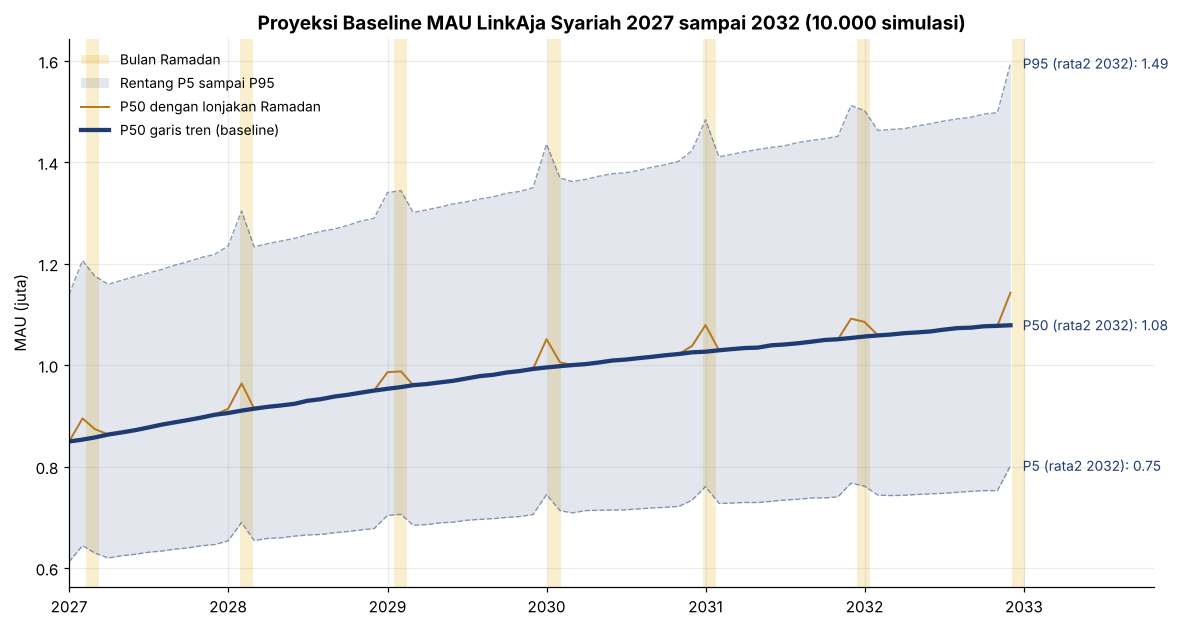

In [16]:
chart_fan(res["MAU"], res["MAU_sa"], np.percentile(target, [5, 50, 95]) / 1e6, f"{OUT}/baseline_proyeksi_MAU.png")

**Cara membaca.** Garis tengah (P50) adalah baseline: pertumbuhan terus melandai sekitar 4% per tahun. Pita P5 sampai P95 menunjukkan seberapa lebar kemungkinan. Level MAU absolut sengaja tidak dijadikan klaim, karena level awal Syariah tidak dipublikasikan.

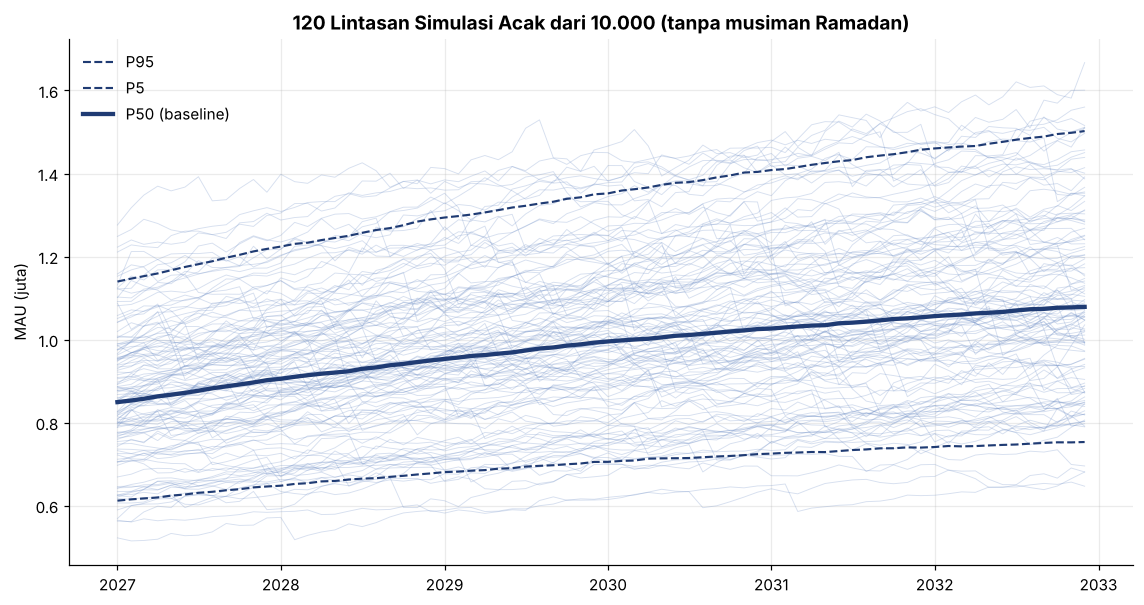

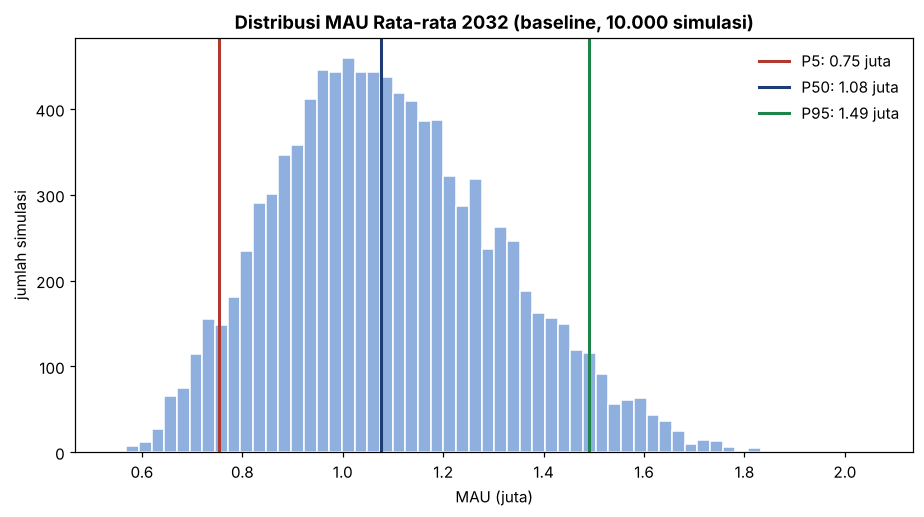

In [17]:
chart_spaghetti(res["MAU_sa"], f"{OUT}/baseline_lintasan_simulasi.png")
chart_hist(target, f"{OUT}/baseline_histogram_MAU_2032.png")

### Apa yang membuat hasil bullish atau bearish?

In [18]:
show(tail_table(res["drivers"], mult))

Faktor,Bearish (<=P5),Semua simulasi,Bullish (>=P95)
Pertumbuhan MAU tahun 1,0.06,0.09,0.12
Pertumbuhan MAU jangka panjang,0.02,0.02,0.02
Kecepatan peluruhan pertumbuhan MAU,0.50,0.45,0.30
Perubahan tekanan kompetisi,0.07,0.05,0.01
Jumlah kejadian khusus (6 tahun),2.64,2.00,1.63
Efek makro kumulatif,-0.07,-0.01,0.00
Sensitivitas MAU terhadap konsumsi,1.55,1.33,1.34
Amplitudo Ramadan,0.06,0.07,0.07


Tabel di atas membandingkan rata-rata parameter pada simulasi terbaik (bullish) dan terburuk (bearish) untuk kelipatan MAU 2032. Parameter yang paling berbeda adalah pendorong utama ketidakpastian.

# BAGIAN 2. Seberapa besar MAU naik dengan solusi Nava?

Solusi diterapkan pada **lintasan baseline yang sama**. Perbandingan memakai **indeks** (MAU Desember 2026 = 100 per simulasi) supaya ketidakpastian level awal, yang sama di kedua dunia, tidak mengaburkan efek solusi. Pita dilaporkan sebagai P10 sampai P90 (80% hasil simulasi).

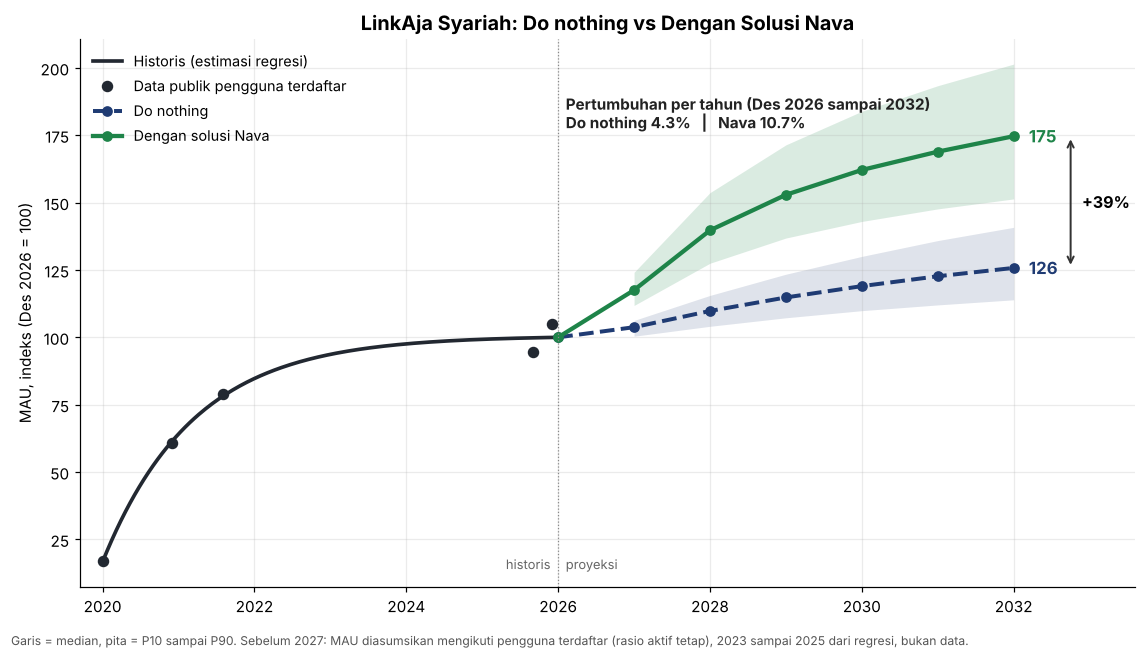

In [19]:
sol = jalankan_solusi(res, N)
chart_utama(res, sol, f"{OUT}/solusi_grafik_utama.png")

**Cara membaca.** Garis hijau adalah median dengan solusi, garis biru putus-putus adalah median do nothing. Pada indeks, batas bawah solusi (P10) berada di atas batas atas do nothing (P90) di setiap tahun. Sebelum 2027, garis historis adalah regresi saturasi eksponensial pada lima titik data pengguna terdaftar (rasio aktif diasumsikan tetap), jadi 2023 sampai 2025 adalah estimasi, bukan data.

In [20]:
print("MAU berindeks (Des 2026 = 100)")
show(tabel_indeks(res, sol), 1)
print("MAU rata-rata tahunan (juta)")
show(tabel_utama(res, sol))

MAU berindeks (Des 2026 = 100)


Tahun,Do nothing P10,Do nothing P50,Do nothing P90,Solusi P10,Solusi P50,Solusi P90,P10 solusi di atas P90 do nothing,Solusi menang di simulasi yang sama (%)
2027,100.4,103.8,106.3,111.8,117.5,124.1,True,100.0
2028,104.1,109.8,115.6,127.5,139.7,153.7,True,100.0
2029,107.3,114.8,123.4,136.9,152.9,171.4,True,100.0
2030,109.9,119.0,130.0,143.0,162.1,183.9,True,100.0
2031,112.0,122.7,135.9,147.7,168.9,193.4,True,100.0
2032,113.9,125.8,140.8,151.4,174.7,201.4,True,100.0


MAU rata-rata tahunan (juta)


Tahun,Do nothing P10,Do nothing P50,Do nothing P90,Solusi P10,Solusi P50,Solusi P90
2027,0.68,0.88,1.12,0.78,1.00,1.28
2028,0.72,0.93,1.19,0.92,1.21,1.47
2029,0.75,0.98,1.25,1.02,1.34,1.57
2030,0.78,1.02,1.31,1.08,1.43,1.64
2031,0.80,1.05,1.36,1.13,1.50,1.70
2032,0.82,1.08,1.40,1.18,1.55,1.74


In [21]:
print("Kenaikan MAU terhadap do nothing pada simulasi yang sama (%)")
show(tabel_uplift_tahun(res, sol), 1)

Kenaikan MAU terhadap do nothing pada simulasi yang sama (%)


Tahun,Kenaikan P10 (%),Kenaikan P50 (%),Kenaikan P90 (%)
2027,9.0,13.3,19.1
2028,17.8,27.2,38.7
2029,20.4,33.4,47.3
2030,20.6,36.4,51.7
2031,20.1,38.1,54.4
2032,19.1,39.4,56.3


In [22]:
show(tabel_ringkasan(res, sol))

Ukuran,Nilai
Kenaikan MAU 2032 P10 (%),19.13
Kenaikan MAU 2032 P50 (%),39.38
Kenaikan MAU 2032 P90 (%),56.33
"MAU 2032 do nothing, P50 (juta)",1.08
"MAU 2032 dengan solusi, P50 (juta)",1.55
"Tambahan MAU 2032, median berpasangan (juta)",0.40
"Pertumbuhan MAU per tahun do nothing, P50 (%)",4.39
"Pertumbuhan MAU per tahun dengan solusi, P50 (%)",10.77
"Pertumbuhan MAU tahun 1 dengan solusi, P50 (%)",18.15
"Kenaikan pengguna terdaftar 2032, P50 (%)",10.47


**Cara membaca.** "Kenaikan" dan "tambahan MAU" dihitung sebagai median selisih per simulasi (berpasangan), jadi bersih dari keberuntungan acak. Pada level absolut, pita do nothing dan solusi masih sedikit saling menimpa karena level awal MAU tidak diketahui. Itu sebabnya perbandingan utama memakai indeks dan simulasi berpasangan.

### Lintasan acak: do nothing vs dengan solusi

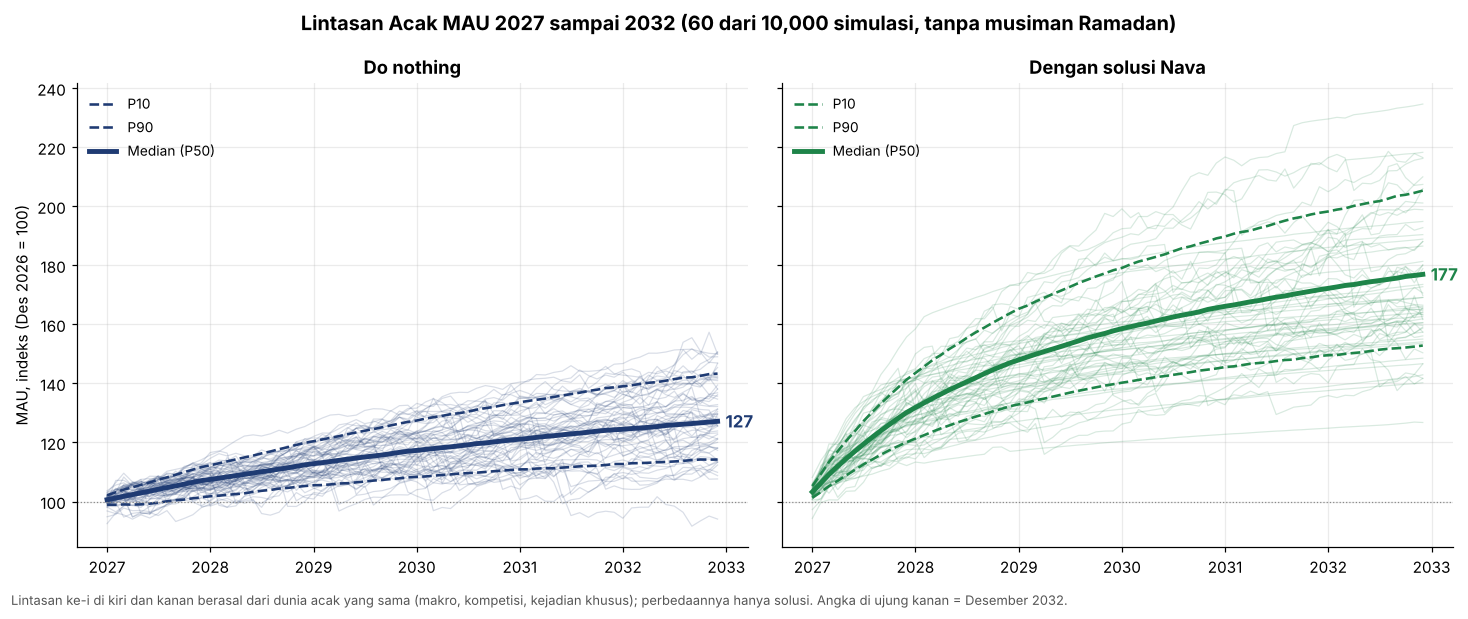

In [23]:
chart_lintasan(res, sol, f"{OUT}/solusi_lintasan_acak.png")

Enam puluh dunia acak yang sama digambar dua kali. Dunia ke-i di kiri dan di kanan memiliki kondisi makro dan kejutan yang sama, jadi perbedaannya hanya solusi.

### Sebaran hasil 2032

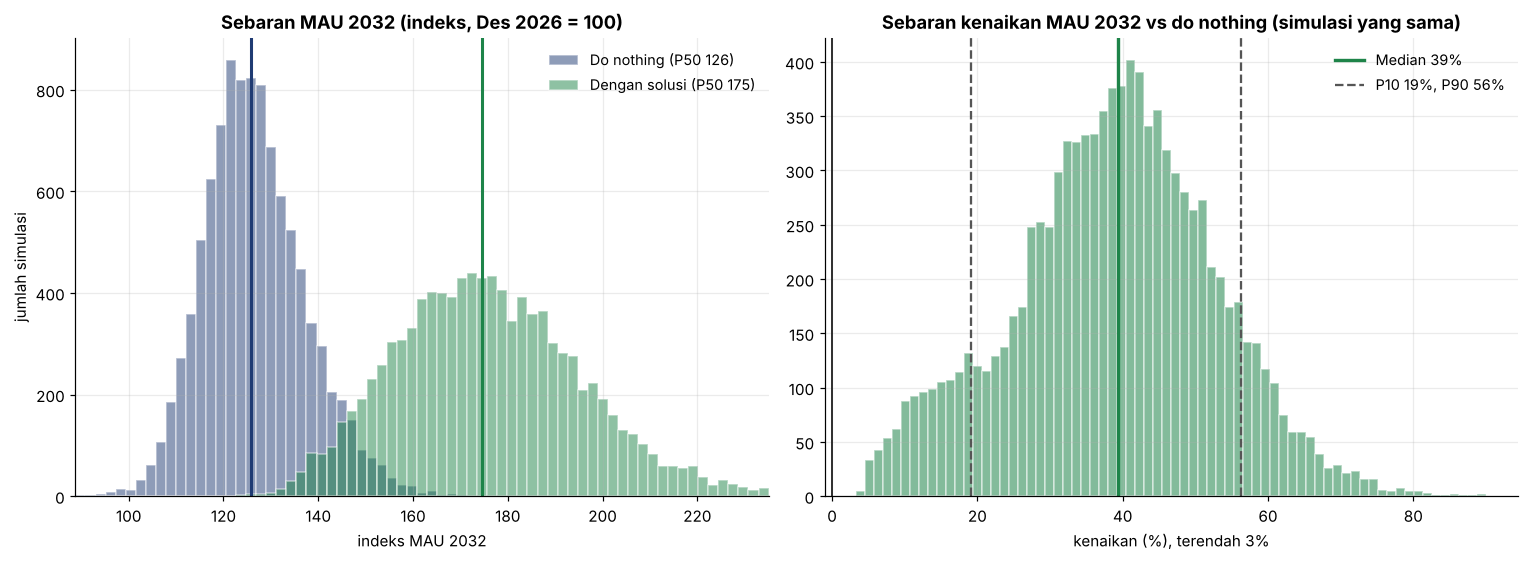

In [24]:
chart_distribusi(res, sol, f"{OUT}/solusi_distribusi_2032.png")

Histogram kiri memperlihatkan sebaran MAU berindeks 2032 untuk kedua dunia. Histogram kanan memperlihatkan sebaran kenaikan pada simulasi yang sama: seluruh simulasi positif, karena efek pilar pada model berarah positif, tetapi besarnya sangat bervariasi.

# BAGIAN 3. Pilar mana yang bekerja?

Tiap pilar dijalankan sendirian pada dunia yang sama, lalu dibandingkan dengan gabungan ketiganya. Jumlah efek tunggal sedikit di atas efek gabungan karena tumpang tindih dan plafon rasio aktif.

Pilar,Kenaikan MAU 2032 P50 (%),P10 (%),P90 (%)
Pilar 1 (aplikasi Nava),19.50,7.51,31.85
Pilar 2 (aktivasi),7.86,4.58,12.28
Pilar 3 (loyalty),14.66,6.88,21.42
Gabungan (setelah tumpang tindih),39.38,19.13,56.33


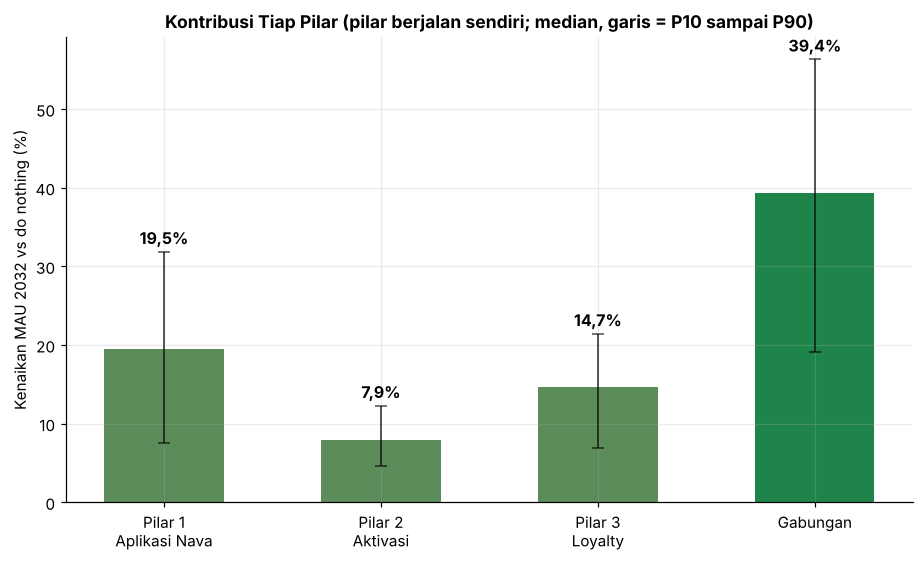

In [25]:
show(tabel_pilar(res, sol))
chart_pilar(res, sol, f"{OUT}/solusi_kontribusi_pilar.png")

**Cara membaca.** Pilar 1 (aplikasi) memberi kontribusi terbesar karena menggeser rasio aktif untuk seluruh basis pengguna. Pilar 2 hanya menambah pengguna baru. Pilar 3 menaikkan retensi dan efeknya bertambah karena menumpuk.

### Asumsi mana yang paling menentukan hasil? (korelasi peringkat Spearman dengan kenaikan MAU 2032)

In [26]:
show(tabel_sensitivitas(res, sol))

parameter,spearman
m1,0.39
u2,0.24
om,0.22
g3,0.17
m3,0.16
q,0.06
t3,-0.03
t1,-0.02
t2,0.00


Parameter pada bagian atas tabel adalah asumsi yang paling layak divalidasi dengan data klien. Waktu efek terbangun (t1, t2, t3) hampir tidak mengubah hasil akhir 2032, tetapi mengubah seberapa cepat dampak terlihat.

# BAGIAN 4. Pertumbuhan per tahun dan titik impas biaya

Angka "kenaikan +39%" adalah selisih terhadap do nothing, bukan pertumbuhan Nava itu sendiri. Pertumbuhan Nava terhadap kondisi hari ini lebih besar, dan dilaporkan di sini sebagai CAGR (laju pertumbuhan per tahun).

In [27]:
c = tabel_cagr(res, sol)
show(pd.DataFrame({
    "Kondisi": c["Kondisi"],
    "CAGR Des 2026 ke 2032, P10 (%/thn)": c.iloc[:, 1], "P50": c.iloc[:, 2], "P90": c.iloc[:, 3],
    "Total pertumbuhan 2032 vs Des 2026, P50 (%)": c.iloc[:, 8]}))

Kondisi,"CAGR Des 2026 ke 2032, P10 (%/thn)",P50,P90,"Total pertumbuhan 2032 vs Des 2026, P50 (%)"
Do nothing,2.40,4.26,6.42,25.77
Dengan solusi Nava,7.83,10.67,13.58,74.66


Pertumbuhan tiap tahun terhadap tahun sebelumnya (2027 dibandingkan MAU Desember 2026):

In [28]:
show(tabel_pertumbuhan_tahunan(res, sol))

Tahun,Do nothing P50 (%),Dengan solusi Nava P50 (%),Dengan solusi Nava P10 (%),Dengan solusi Nava P90 (%)
2027,3.76,17.54,11.83,24.13
2028,6.12,19.07,12.07,25.57
2029,4.88,9.52,4.57,14.41
2030,3.94,5.63,2.54,10.14
2031,3.31,3.79,1.57,8.03
2032,2.83,2.94,0.96,6.84


**Cara membaca.** Pertumbuhan Nava paling besar pada 2027 sampai 2028 saat pilar 1 dan 2 terbangun, lalu melandai. Retensi yang menumpuk (G3) menjaga Nava tetap di atas do nothing pada 2030 sampai 2031, tetapi pada 2032 selisihnya hampir hilang. Penyebabnya: efek pilar 1 dan 2 adalah lonjakan level sekali jalan, dan plafon rasio aktif 12,5% sudah menahan hasil pada sekitar separuh simulasi pada 2032. Plafon itu berasal dari satu pembanding (Muslim Pro), sehingga melonggarkannya adalah keputusan tim, bukan hasil data.

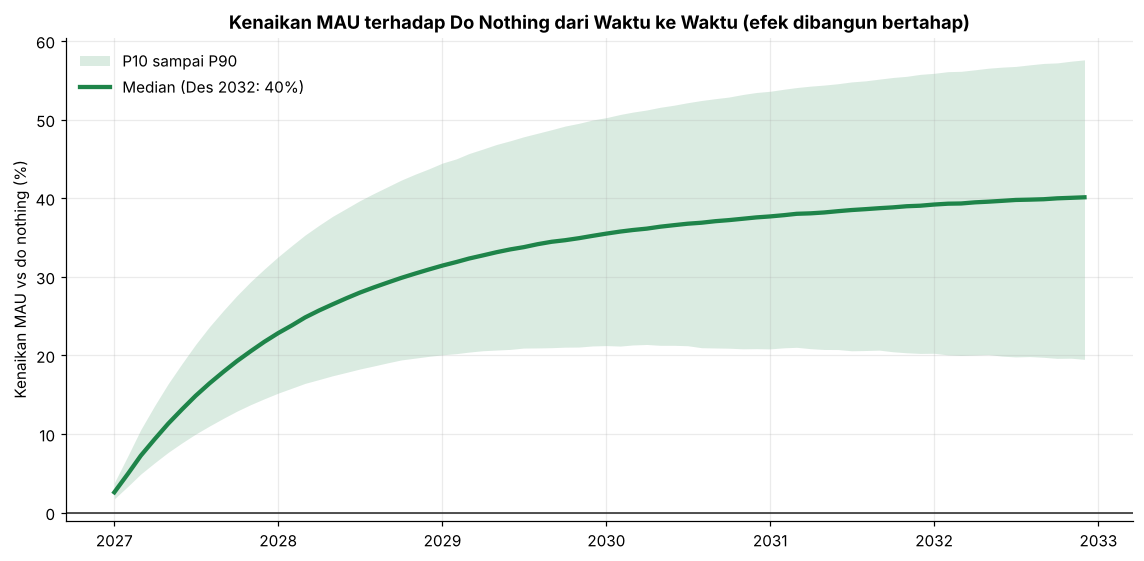

In [29]:
chart_uplift(res, sol, f"{OUT}/solusi_kenaikan_per_waktu.png")

### Titik impas biaya

Pertanyaan "apakah biaya sepadan" dijawab dengan titik impas, bukan persentase kenaikan. Tabel menunjukkan pendapatan bersih minimal per MAU tambahan per tahun agar biaya tertutup. **Biaya di bawah adalah angka ilustrasi, bukan biaya proposal.** Level MAU absolut bergantung pada asumsi MAU awal, jadi hitungan ini harus diulang dengan angka klien.

In [30]:
show(tabel_titik_impas(res, sol))

"Total biaya 2027 sampai 2032 (Rp miliar, ilustrasi)",Tahun-pengguna tambahan P10 / P50 / P90 (juta),"Pendapatan bersih minimal per MAU tambahan per tahun, pada P90 (Rp ribu)","Pendapatan bersih minimal per MAU tambahan per tahun, pada P50 (Rp ribu)","Pendapatan bersih minimal per MAU tambahan per tahun, pada P10 (Rp ribu)"
10,1.20 / 1.84 / 2.54,3.94,5.45,8.33
25,1.20 / 1.84 / 2.54,9.86,13.62,20.82
50,1.20 / 1.84 / 2.54,19.72,27.25,41.64
100,1.20 / 1.84 / 2.54,39.44,54.49,83.28


# BAGIAN 5. Peluang solusi berhasil

Hasil di atas menjawab "berapa dampaknya bila pilar berjalan seperti dirancang". Pertanyaan yang berbeda: **berapa peluang solusi ini benar-benar berhasil**, bila sebuah pilar bisa gagal total (misalnya aplikasi sepi unduhan atau kampanye tidak menghasilkan pendaftar)?

**Metode.** Pada tiap simulasi, tiap pilar gagal total dengan peluang awal *f*. Pilar 3 hanya berjalan bila aplikasi (pilar 1) berjalan. Besar efek pilar tidak diubah untuk mendapatkan angka tertentu. Nilai *f* adalah asumsi karena tidak ada data kegagalan pilar untuk LinkAja. Sebagai rujukan kasar, literatur peluncuran produk konsumen menaksir kegagalan sekitar 25% sampai 45% (sumber sekunder, bukan aplikasi keuangan), jadi angka utama dipakai pada **f = 30%** dan rentang 0% sampai 40% ditampilkan.

**Rancangan mitigasi** (hanya sah bila benar-benar ada di rencana implementasi proposal):
- **Pilar 1, uji coba bertahap.** Bila peluncuran pertama gagal, aplikasi diperbaiki dan diluncurkan ulang satu kali. Peluang gagal lagi 50%, efek tertunda 9 bulan.
- **Pilar 2 dan 3, kanal paralel.** Aktivasi memakai tiga kelompok kanal dan loyalty memakai tiga fitur. Pilar gagal hanya bila ketiganya gagal, ditambah peluang 10% gagal karena sebab bersama.

Ketiga angka mitigasi (10%, 50%, 9 bulan) adalah asumsi tim.

**Definisi berhasil** (semuanya dilaporkan agar tidak bergantung satu ambang): lebih tinggi dari do nothing; kenaikan MAU 2032 minimal 10%, 20%, atau 30%; dan MAU 2032 melewati P90 do nothing.

In [31]:
tp = tabel_peluang(res, sol)
tp.columns = ["Rancangan", "f awal (%)", "Lebih baik dari do nothing", "Naik min 10%", "Naik min 20%",
              "Naik min 30%", "Lewat P90 do nothing", "Kenaikan median (%)", "Target dengan keyakinan 80% (%)"]
show(tp[tp["Rancangan"] == "Tanpa mitigasi"], 1)
show(tp[(tp["Rancangan"] == "Dengan mitigasi") & (tp["f awal (%)"] > 0)], 1)

Rancangan,f awal (%),Lebih baik dari do nothing,Naik min 10%,Naik min 20%,Naik min 30%,Lewat P90 do nothing,Kenaikan median (%),Target dengan keyakinan 80% (%)
Tanpa mitigasi,0.0,100.0,97.7,89.2,75.1,69.7,39.4,27.6
Tanpa mitigasi,10.0,98.7,89.1,77.5,61.0,61.2,34.8,18.1
Tanpa mitigasi,20.0,95.5,80.6,66.3,49.0,53.7,29.5,10.2
Tanpa mitigasi,30.0,90.2,71.7,55.8,38.5,46.5,24.0,7.2
Tanpa mitigasi,40.0,83.1,62.2,45.8,29.2,39.8,16.8,4.3


Rancangan,f awal (%),Lebih baik dari do nothing,Naik min 10%,Naik min 20%,Naik min 30%,Lewat P90 do nothing,Kenaikan median (%),Target dengan keyakinan 80% (%)
Dengan mitigasi,10.0,99.3,93.1,81.9,64.6,63.7,35.9,21.4
Dengan mitigasi,20.0,98.6,89.4,77.7,61.1,61.2,34.7,18.3
Dengan mitigasi,30.0,97.8,85.9,73.3,57.0,58.3,33.1,14.1
Dengan mitigasi,40.0,96.6,81.4,67.7,51.5,54.5,30.8,10.7


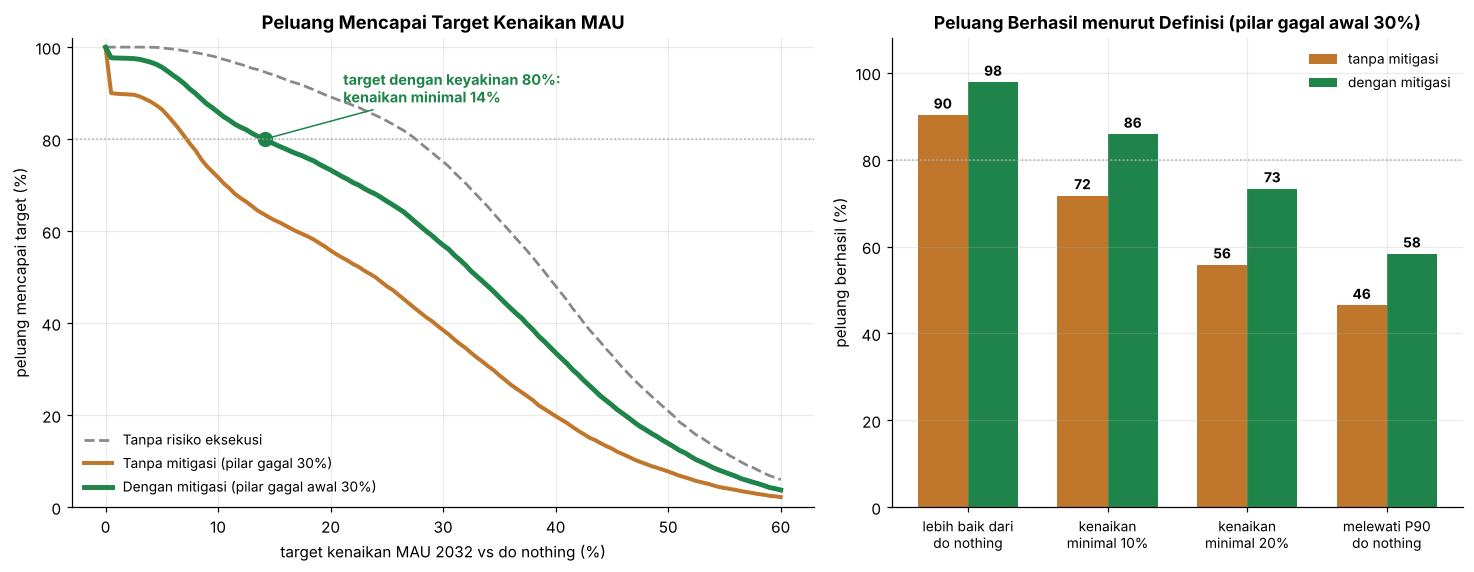

In [32]:
chart_peluang(res, sol, f"{OUT}/solusi_peluang_berhasil.png")

**Cara membaca.**
- Grafik kiri: untuk setiap target kenaikan MAU (sumbu x), berapa peluang solusi mencapainya (sumbu y). Titik hijau adalah **target yang dapat dijanjikan dengan keyakinan 80%**.
- Grafik kanan: peluang berhasil untuk empat definisi, tanpa dan dengan mitigasi, pada f = 30%.
- Peluang di atas 80% tercapai pada definisi yang longgar (lebih baik dari do nothing, kenaikan minimal 10%). Untuk definisi yang lebih ketat (minimal 20% atau melewati P90 do nothing), peluangnya lebih rendah, dan tidak dinaikkan dengan mengubah efek pilar.
- Cara lazim menyatakan target adalah nilai yang dilampaui dengan peluang tertentu, bukan nilai tengah.

### Pilar mana yang berjalan pada tiap kondisi? (f awal 30%)

In [33]:
print("Tanpa mitigasi")
show(tabel_kondisi(res, sol, mitigasi=False))
print("Dengan mitigasi")
show(tabel_kondisi(res, sol, mitigasi=True))

Tanpa mitigasi


Pilar yang berjalan,Peluang kondisi (%),Kenaikan MAU median (%),Peluang melewati P90 do nothing (%)
Pilar 1 + Pilar 2 + Pilar 3,34.76,38.97,69.02
Pilar 2,20.63,7.85,18.52
Pilar 1 + Pilar 2,15.03,26.08,47.24
Pilar 1 + Pilar 3,14.23,29.27,55.80
Tidak ada yang berjalan,9.15,0.00,10.16
Pilar 1,6.20,19.47,43.23


Dengan mitigasi


Pilar yang berjalan,Peluang kondisi (%),Kenaikan MAU median (%),Peluang melewati P90 do nothing (%)
Pilar 1 + Pilar 2 + Pilar 3,66.37,39.13,68.62
Pilar 2,12.31,7.92,18.36
Pilar 1 + Pilar 2,9.16,25.84,49.67
Pilar 1 + Pilar 3,8.91,29.03,57.80
Tidak ada yang berjalan,1.97,0.00,11.68
Pilar 1,1.28,20.29,45.31


**Keterbatasan metode.** Kegagalan dibuat biner dan sebagian besar saling bebas. Pada kenyataannya pilar bisa gagal sebagian dan berkorelasi (anggaran dan tim yang sama), sehingga hasil nyata lebih bergelombang daripada model ini.

## Angka utama untuk proposal

In [34]:
yb = yearly(res["MAU_sa"])[0]; ys = yearly(sol["mau_sa"])[0]; m0 = res["MAU0"]
cg_b = ((yb[:, -1] / m0) ** (1 / TAHUN_EFEKTIF) - 1) * 100
cg_s = ((ys[:, -1] / m0) ** (1 / TAHUN_EFEKTIF) - 1) * 100
up = (yearly(sol["mau"])[0][:, -1] / yearly(res["MAU"])[0][:, -1] - 1) * 100
q = lambda x: np.percentile(x, [10, 50, 90])
tp2 = tabel_peluang(res, sol)
mit = tp2[(tp2["Rancangan"] == "Dengan mitigasi") & (tp2["Peluang pilar gagal awal (%)"] == 30)].iloc[0]
print(f"Kenaikan MAU 2032 vs do nothing     : P50 {q(up)[1]:.0f}%  (P10 {q(up)[0]:.0f}%, P90 {q(up)[2]:.0f}%)")
print(f"Pertumbuhan MAU per tahun           : do nothing {np.median(cg_b):.1f}%  vs  Nava {np.median(cg_s):.1f}%")
print(f"Total pertumbuhan 2032 vs Des 2026  : do nothing +{np.median(yb[:, -1] / m0 - 1) * 100:.0f}%  vs  Nava +{np.median(ys[:, -1] / m0 - 1) * 100:.0f}%")
print(f"Solusi menang di simulasi yang sama : {np.mean(ys[:, -1] > yb[:, -1]) * 100:.0f}%")
print(f"Dengan mitigasi, f awal 30%         : lebih baik dari do nothing {mit.iloc[2]:.0f}%, naik min 10% {mit.iloc[3]:.0f}%, "
      f"naik min 20% {mit.iloc[4]:.0f}%")
print(f"Target dengan keyakinan 80%         : kenaikan MAU minimal {mit.iloc[8]:.0f}% pada 2032")

Kenaikan MAU 2032 vs do nothing     : P50 39%  (P10 19%, P90 56%)
Pertumbuhan MAU per tahun           : do nothing 4.3%  vs  Nava 10.7%
Total pertumbuhan 2032 vs Des 2026  : do nothing +26%  vs  Nava +75%
Solusi menang di simulasi yang sama : 100%
Dengan mitigasi, f awal 30%         : lebih baik dari do nothing 98%, naik min 10% 86%, naik min 20% 73%
Target dengan keyakinan 80%         : kenaikan MAU minimal 14% pada 2032


## Asumsi dan keterbatasan (taruh di lampiran)

1. **Semua rentang efek pilar adalah asumsi tim.** Jangkarnya tidak langsung: rasio Muslim Pro adalah batas atas, bukan bukti efek Nava. Tidak ada data konversi KOL atau QRIS masjid untuk LinkAja.
2. **Bukti retensi berkualitas rendah.** Data gamifikasi berasal dari agensi dan blog perusahaan; tinjauan akademik (Hamari dkk., 2014) menyatakan efeknya bergantung konteks. **Retensi yang menumpuk (G3) adalah asumsi tanpa data.** Tanpa G3 kenaikan median 2032 sekitar 34%.
3. **Pernyataan DMI "hingga 10 kali lipat"** adalah pernyataan pejabat organisasi, bukan studi.
4. **Linimasa diasumsikan** Nava aktif sejak Januari 2027 dengan anggaran terjaga.
5. **Tambahan pendaftar dari aplikasi (U1) dibuat nol** agar konservatif; bisa dinaikkan bila ada dasar.
6. **Survei internal (n=50)** adalah mahasiswa Gen Z dan bersifat indikatif, bukan representatif nasional.
7. **Dampak finansial belum dihitung.** Konversi tambahan MAU menjadi pendapatan butuh pendapatan per pengguna aktif dari klien. Titik impas di Bagian 4 memakai biaya ilustrasi.
8. **Peluang gagal pilar (f) dan parameter mitigasi adalah asumsi.** Rujukannya literatur produk konsumen (sumber sekunder).
9. **Riwayat sebelum 2027** adalah regresi pada lima titik pengguna terdaftar dengan rasio aktif tetap; 2023 sampai 2025 adalah estimasi.
10. **Plafon rasio aktif 12,5%** berasal dari satu pembanding (Muslim Pro, sekitar 5 juta aktif dari 40 juta terdaftar, Bisnis.com 2025).
11. **Perlu dicek ke sumber primer:** angka MAU Syariah dari klien, selisih 9 juta (Kontan) dengan 10 juta (kasus) pengguna terdaftar, dan data retensi.

**Referensi metode.** Bass (1969), *Management Science* 15(5); Metropolis & Ulam (1949), *JASA* 44(247); Merton (1976), *Journal of Financial Economics* 3(1-2); Malcolm dkk. (1959), *Operations Research* 7(5); Saltelli dkk. (2008), *Global Sensitivity Analysis: The Primer*; Hamari, Koivisto & Sarsa (2014), HICSS; Henderson (1970), BCG.